# Praktikum 2 - Eksplorasi Lanjutan K-Means dan Algoritma Expectation-Maximization

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 04:** Klasterisasi

### Topik Praktikum:
1. Pengantar K-Means pada dataset sintetis `make_blobs`.
2. Implementasi algoritma Expectation-Maximization (EM) secara manual.
3. Penanganan batas klaster non-linier (`make_moons`) dengan Spectral Clustering.
4. Studi Kasus 1: Klasterisasi dan Proyeksi t-SNE pada Dataset Digit Angka.
5. Studi Kasus 2: Kompresi Warna Citra Menggunakan MiniBatchKMeans.

## 1. Pengantar K-Means pada Data Blobs

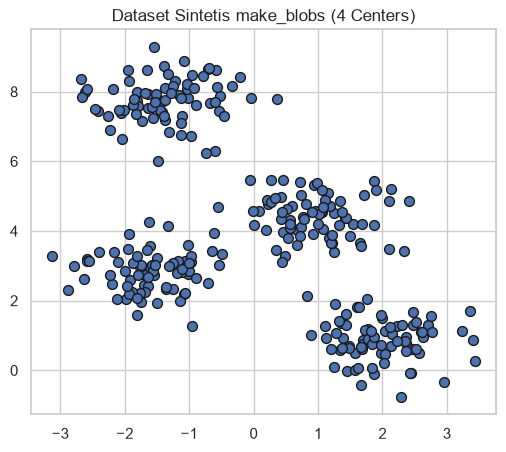

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_theme(style='whitegrid')
from sklearn.datasets import make_blobs, make_moons, load_digits, load_sample_image
from sklearn.cluster import KMeans, SpectralClustering, MiniBatchKMeans
from sklearn.metrics import pairwise_distances_argmin, accuracy_score, confusion_matrix
from scipy.stats import mode

X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], s=50, edgecolors='k')
plt.title('Dataset Sintetis make_blobs (4 Centers)')
plt.show()

C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


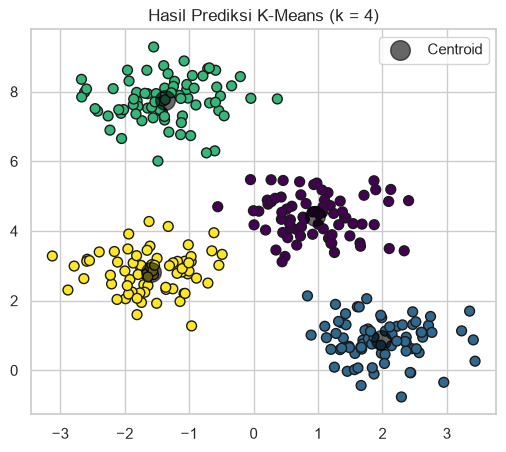

In [2]:
kmeans = KMeans(n_clusters=4, random_state=0, n_init='auto')
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis', edgecolors='k')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.6, marker='o', label='Centroid')
plt.title('Hasil Prediksi K-Means (k = 4)')
plt.legend()
plt.show()

## 2. Implementasi Manual Algoritma Expectation-Maximization (EM)

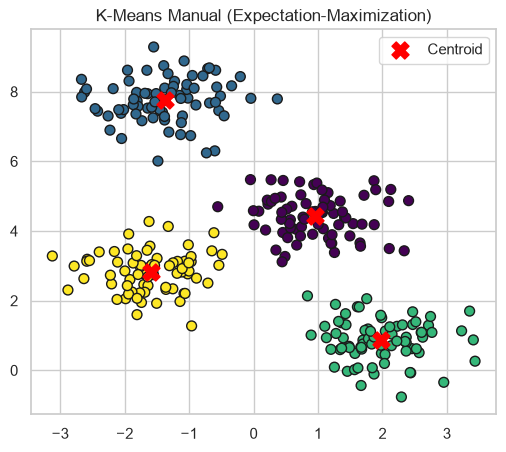

In [3]:
def find_clusters(X, n_clusters, rseed=2):
    rng = np.random.RandomState(rseed)
    i = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[i]
    while True:
        # Step E: Tentukan label terdekat ke centroid
        labels = pairwise_distances_argmin(X, centers)
        # Step M: Hitung ulang centroid baru dari mean titik
        new_centers = np.array([X[labels == i].mean(0) for i in range(n_clusters)])
        if np.all(centers == new_centers):
            break
        centers = new_centers
    return centers, labels

centers, labels = find_clusters(X, 4, rseed=2)
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis', edgecolors='k')
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=150, marker='X', label='Centroid')
plt.title('K-Means Manual (Expectation-Maximization)')
plt.legend()
plt.show()

## 3. Batas Klaster Non-Linier: K-Means vs Spectral Clustering

C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


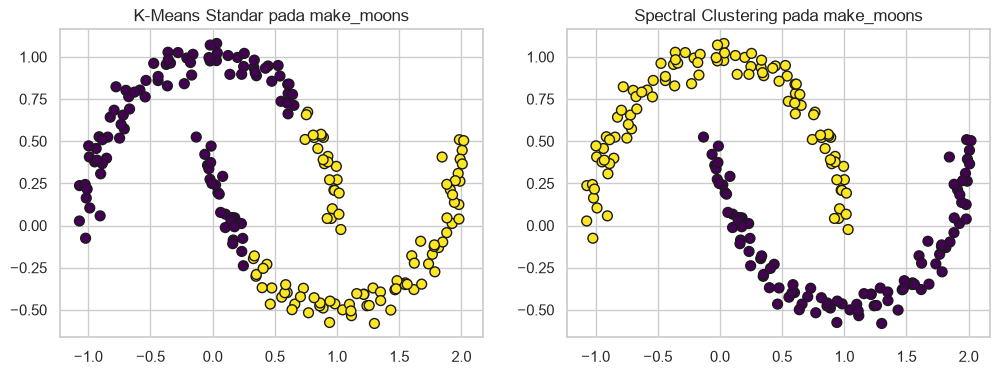

In [4]:
X_moons, y_moons = make_moons(200, noise=0.05, random_state=0)

# K-Means Standar (Gagal memisahkan struktur non-linier berbentuk bulan sabit)
labels_km = KMeans(2, random_state=0, n_init='auto').fit_predict(X_moons)

# Spectral Clustering (Mampu memetakan manifold non-linier)
model_spec = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', assign_labels='kmeans', random_state=0)
labels_spec = model_spec.fit_predict(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=labels_km, s=50, cmap='viridis', edgecolors='k')
axes[0].set_title('K-Means Standar pada make_moons')

axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=labels_spec, s=50, cmap='viridis', edgecolors='k')
axes[1].set_title('Spectral Clustering pada make_moons')
plt.show()

## 4. Studi Kasus 1: Klasterisasi Dataset Digit dan t-SNE

In [5]:
digits = load_digits()
print('Dimensi data digit:', digits.data.shape)

kmeans_digits = KMeans(n_clusters=10, random_state=0, n_init='auto')
clusters = kmeans_digits.fit_predict(digits.data)

# Pemetaan label cluster ke label kelas target asli
labels_mapped = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    if np.sum(mask) > 0:
        labels_mapped[mask] = mode(digits.target[mask], keepdims=True)[0][0]

acc = accuracy_score(digits.target, labels_mapped)
print(f'Akurasi K-Means pada Digits asli: {acc:.4f}')

# Proyeksi t-SNE ke 2 dimensi kemudian di-klaster
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, init='random', random_state=0)
digits_proj = tsne.fit_transform(digits.data)

clusters_tsne = KMeans(n_clusters=10, random_state=0, n_init='auto').fit_predict(digits_proj)
labels_tsne = np.zeros_like(clusters_tsne)
for i in range(10):
    mask = (clusters_tsne == i)
    if np.sum(mask) > 0:
        labels_tsne[mask] = mode(digits.target[mask], keepdims=True)[0][0]

acc_tsne = accuracy_score(digits.target, labels_tsne)
print(f'Akurasi K-Means setelah Proyeksi t-SNE: {acc_tsne:.4f}')

Dimensi data digit: (1797, 64)
Akurasi K-Means pada Digits asli: 0.7440


Akurasi K-Means setelah Proyeksi t-SNE: 0.9410


## 5. Studi Kasus 2: Kompresi Warna Citra (16 Warna)

C:\Users\luvma\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1965: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 2048 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


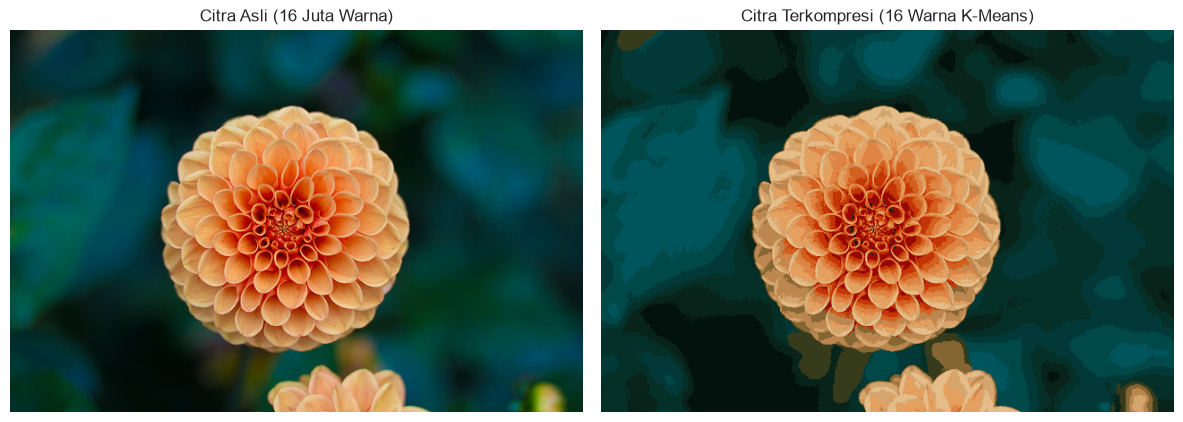

In [6]:
flower = load_sample_image('flower.jpg')
data_img = flower / 255.0
data_img = data_img.reshape(-1, 3)

kmeans_color = MiniBatchKMeans(16, random_state=0, n_init='auto')
kmeans_color.fit(data_img)
new_colors = kmeans_color.cluster_centers_[kmeans_color.predict(data_img)]
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(flower)
ax[0].set_title('Citra Asli (16 Juta Warna)')
ax[0].axis('off')

ax[1].imshow(flower_recolored)
ax[1].set_title('Citra Terkompresi (16 Warna K-Means)')
ax[1].axis('off')
plt.tight_layout()
plt.show()